In [9]:
import numpy as np
import matplotlib as plt
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split

In [10]:
df = pd.read_csv("sensor_kompresor.csv")
display(df.info())
df = df.drop_duplicates().sort_values("timestamp").reset_index(drop=True)
display(df.describe())
display(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4317 entries, 0 to 4316
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   timestamp   4317 non-null   object 
 1   suhu_ruang  4317 non-null   float64
 2   suhu_motor  4304 non-null   float64
 3   getaran     4305 non-null   float64
 4   tekanan     4305 non-null   float64
 5   arus        4305 non-null   float64
 6   rpm         4317 non-null   float64
dtypes: float64(6), object(1)
memory usage: 236.2+ KB


None

,suhu_ruang,suhu_motor,getaran,tekanan,arus,rpm
count,4311.000000,4299.000000,4299.000000,4299.000000,4299.000000,4311.000000
mean,29.511492,49.704080,1.773688,4.496197,26.970309,864.768499
std,2.139348,16.480237,1.297941,2.868357,21.066669,728.855104
min,25.770000,26.880000,0.200000,0.640000,0.300000,0.000000
25%,27.420000,29.880000,0.278000,1.070000,1.825000,2.000000
50%,29.510000,61.540000,2.539000,6.810000,43.400000,1474.000000
75%,31.580000,64.380000,2.767500,7.000000,45.350000,1481.000000
max,33.380000,88.400000,11.800000,11.900000,79.000000,1499.000000


timestamp      0
suhu_ruang     0
suhu_motor    12
getaran       12
tekanan       12
arus          12
rpm            0
dtype: int64

In [11]:
df['status'] = np.where(df["rpm"] > 100, "on", "off")

In [12]:
sensor = ["suhu_motor", "getaran", "tekanan", "arus"]
df[sensor] = df[sensor].interpolate(limit=3)   # celah kecil saja
df = df.dropna(subset=sensor)                  # sisa celah besar dibuang

AttributeError: module 'matplotlib' has no attribute 'show'

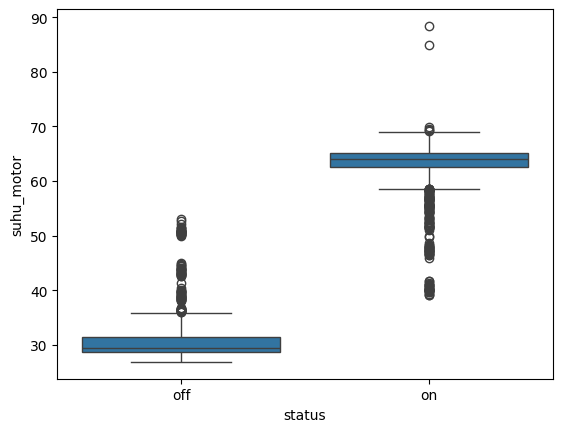

In [13]:
for c in sensor:
    sns.boxplot(data=df, x="status", y=c); plt.show()
    df.plot(x="timestamp", y=c, figsize=(12,3)); plt.show()

In [14]:
def flag_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - k*iqr) | (s > q3 + k*iqr)

for c in sensor:
    df[f"{c}_out"] = df.groupby("status")[c].transform(flag_iqr)
df["anom_stat"] = df[[f"{c}_out" for c in sensor]].any(axis=1)

In [15]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

df["anom_if"] = False
for st, g in df.groupby("status"):
    X = StandardScaler().fit_transform(g[sensor + ["suhu_ruang"]])
    pred = IsolationForest(contamination=0.02, random_state=42).fit_predict(X)
    df.loc[g.index, "anom_if"] = pred == -1

In [16]:
for c in sensor:
    df[f"{c}_diff"] = df[c].diff()
    df[f"{c}_rstd"] = df[c].rolling(6).std()
